# Сказочный бот — эксперимент 3: ранг LoRA 64 (гипотеза 3)

Продолжение ноутбука 2 (`02_experiments.ipynb`). Все обозначения те же.

**Гипотеза 3.** Ранг адаптера LoRA r = 16 (6,29 млн обучаемых параметров) может быть слишком мал, чтобы модель научилась называть героев из подсказки. Проверяем r = 64 (25,2 млн обучаемых параметров, в 4 раза больше) при тех же данных (подсказки с героями главы), тех же настройках обучения и тех же 250 тестовых подсказках, что и для v4. Множитель адаптера lora_alpha берётся пропорционально: 2·r = 128, чтобы масштаб поправки не менялся.

**Что нужно для запуска:**
- Kaggle: два датасета в Input (`fairytale-dataset` с файлами `train.jsonl`, `val.jsonl`, `test.jsonl` и `fairytale-adapter-v4` с архивом адаптера v4, загруженным как есть), в настройках GPU T4 и Internet On.
- Colab: на Диске в `Fairytale_AI_constructor/dataset` данные, в `Fairytale_AI_constructor/stage5/adapter_v4` файлы адаптера v4.

Время: обучение около 80 минут, оценка около 15 минут. Не закрывайте вкладку и отключите спящий режим на компьютере. Чтобы запуск не зависел от компьютера, на Kaggle можно выбрать «Save Version → Save & Run All (Commit)».

## 1. Установка библиотек

In [17]:
!pip install -q peft pymorphy3 pymorphy3-dicts-ru
!pip uninstall -y -q torchao

## 2. Настройки и пути

Режим (Kaggle или Colab) определяется автоматически.

In [18]:
import glob, os

MEDIUM = "ai-forever/rugpt3medium_based_on_gpt2"


def find_dir(filename, root="/kaggle/input", contains=""):
    hits = [h for h in glob.glob(os.path.join(root, "**", filename), recursive=True) if contains in h]
    if not hits:
        raise FileNotFoundError(f"Файл {filename} не найден в {root} (фильтр: '{contains}').")
    return os.path.dirname(hits[0])


if os.path.exists("/kaggle/working"):
    BASE = "/kaggle/working"
    DATA_DIR = find_dir("train.jsonl")
    try:
        ADAPTER_V4 = find_dir("adapter_config.json", contains="v4")
    except FileNotFoundError:
        # если в имени датасета нет «v4», берём любой адаптер и показываем, что нашли
        print("Адаптеров в Input:", glob.glob("/kaggle/input/**/adapter_config.json", recursive=True))
        ADAPTER_V4 = find_dir("adapter_config.json")
else:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/Fairytale_AI_constructor"
    DATA_DIR = BASE + "/dataset"
    ADAPTER_V4 = BASE + "/stage5/adapter_v4"

OUT_DIR = BASE + "/runs/experiments_rank64"
V5_DIR = BASE + "/runs/rugpt3medium_lora_v5_r64"
V5_ADAPTER = os.path.join(V5_DIR, "adapter")

N_PROMPTS = 50
CONTEXT = 2048
MAX_NEW_TOKENS = 350
GEN_BATCH = 10
TOP_P, TEMPERATURE = 0.92, 0.8
SEED = 42
GEN = dict(repetition_penalty=1.0, no_repeat_ngram_size=4)
print("DATA_DIR:", DATA_DIR, "\nADAPTER_V4:", ADAPTER_V4)

DATA_DIR: /kaggle/input/datasets/alyonapudzha/fairytale-datasets 
ADAPTER_V4: /kaggle/input/datasets/alyonapudzha/fairytale-adapter-v4/adapter


## 3. Данные и проверочные подсказки (те же 250, что в ноутбуке 2)

In [20]:
import json, os, random, re, time

import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel
import pymorphy3

device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(OUT_DIR, exist_ok=True)
print("Устройство:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")


def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def pick_eval_set(test_raw, tok, n=N_PROMPTS, context=CONTEXT, max_new=MAX_NEW_TOKENS, seed=SEED):
    # Тот же отбор, что в ноутбуке этапа 4, поэтому подсказки совпадают
    pool = [ex for ex in test_raw
            if len(tok.encode(ex["prompt"], add_special_tokens=False)) <= context - max_new]
    random.seed(seed)
    return random.sample(pool, min(n, len(pool)))


train_raw = load_jsonl(os.path.join(DATA_DIR, "train.jsonl"))
test_raw = load_jsonl(os.path.join(DATA_DIR, "test.jsonl"))
tok = AutoTokenizer.from_pretrained(MEDIUM)
eval_set = pick_eval_set(test_raw, tok)
prompts = [ex["prompt"] for ex in eval_set]
print(f"train: {len(train_raw)}, test: {len(test_raw)}, подсказок для проверки: {len(prompts)}")
print()
print(prompts[0])

Устройство: cuda Tesla T4


config.json:   0%|          | 0.00/761 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.25k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.61M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.27M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/574 [00:00<?, ?B/s]

train: 2810, test: 267, подсказок для проверки: 50

Настроение: adventure
Герои: младший королевич, старший королевич, карлик
Место: королевство, горные ущелья и заколдованный замок
Цель: добыть живую воду, чтобы исцелить больного отца
Мораль: гордость и коварство наказываются, а доброта и смирение вознаграждаются
Предыдущие главы: нет
Выбор ребёнка: Отправиться за живой водой
Глава 1 из 4:



## 4. Метрики

In [21]:
morph = pymorphy3.MorphAnalyzer()
_cache = {}

GENERIC = {"мальчик", "девочка", "мать", "мама", "отец", "папа", "сын", "дочь", "брат", "сестра",
           "старик", "старуха", "дед", "баба", "царь", "король", "принц", "принцесса", "царевна",
           "молодой", "маленький", "старый", "большой", "добрый", "злой", "бедный"}
JUNK_RE = re.compile(r"&\w+;|&#\d+|<[^>]{1,30}>|https?://|www\.")


def lemmas(text):
    # Слова текста в начальной форме (результат кэшируется)
    out = []
    for w in re.findall(r"[а-яё]+", text.lower()):
        lemma = _cache.get(w)
        if lemma is None:
            lemma = morph.parse(w)[0].normal_form.replace("ё", "е")
            _cache[w] = lemma
        out.append(lemma)
    return out


def prompt_heroes(prompt):
    # Герои из строки «Герои:» подсказки
    for line in prompt.splitlines():
        if line.startswith("Герои:"):
            return [h.strip() for h in line[len("Герои:"):].split(",") if h.strip()]
    return []


def hero_keys(hero):
    ls = [l for l in lemmas(hero) if len(l) >= 2]
    specific = [l for l in ls if l not in GENERIC]
    return specific or ls


def hero_coverage(prompt, text):
    # Доля героев подсказки, названных в тексте
    heroes = prompt_heroes(prompt)
    if not heroes:
        return None
    present = set(lemmas(text))
    hits = [all(k in present for k in hero_keys(h)) for h in heroes]
    return sum(hits) / len(hits)


def is_junk(text):
    letters = re.findall(r"[A-Za-zА-Яа-яЁё]", text)
    if not letters:
        return True
    latin = sum(c.isascii() for c in letters)
    return bool(JUNK_RE.search(text)) or latin / len(letters) > 0.1


def repeat_rate(text, n=3):
    words = re.findall(r"[а-яё]+", text.lower())
    grams = list(zip(*[words[i:] for i in range(n)]))
    return 1 - len(set(grams)) / len(grams) if grams else 0.0


def mean(xs):
    xs = list(xs)
    return sum(xs) / len(xs) if xs else float("nan")


def score(prompts, texts):
    cov = [c for c in (hero_coverage(p, t) for p, t in zip(prompts, texts)) if c is not None]
    return {
        "hero_coverage": mean(cov),
        "all_heroes": mean(c == 1.0 for c in cov),
        "junk": mean(is_junk(t) for t in texts),
        "repeat3": mean(repeat_rate(t) for t in texts),
        "words": mean(len(t.split()) for t in texts),
        "n": len(texts),
    }


# Эталон: настоящие главы, обрезанные до той же длины, что и сгенерированные
REF_NAME = "эталон: настоящие главы"
ref_texts = [tok.decode(tok.encode(ex["completion"].replace("</s>", ""), add_special_tokens=False)[:MAX_NEW_TOKENS])
             for ex in eval_set]
results = {REF_NAME: score(prompts, ref_texts)}
print(REF_NAME, {k: round(v, 3) for k, v in results[REF_NAME].items()})

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


эталон: настоящие главы {'hero_coverage': 0.509, 'all_heroes': 0.18, 'junk': 0.0, 'repeat3': 0.007, 'words': 210.9, 'n': 50}


## 5. Подсказки с героями главы

Тот же приём, что в эксперименте 2: в подсказке остаются только герои, названные в тексте главы.

In [22]:
def keep_chapter_heroes(ex):
    # Возвращает копию примера, где в строке «Герои:» остались только герои, названные в главе.
    # Если таких нет, возвращает None.
    heroes = prompt_heroes(ex["prompt"])
    present = set(lemmas(ex["completion"].replace("</s>", "")))
    kept = [h for h in heroes if all(k in present for k in hero_keys(h))]
    if not kept:
        return None
    new_prompt = re.sub(r"^Герои:.*$", "Герои: " + ", ".join(kept), ex["prompt"], count=1, flags=re.M)
    return {**ex, "prompt": new_prompt}


def build_filtered(raw, name, out_dir):
    # Применяет фильтр ко всем примерам, печатает статистику и сохраняет файл на Диск
    items = [keep_chapter_heroes(ex) for ex in raw]
    kept = [i for i in items if i is not None]
    print(f"{name}: было {len(raw)}, осталось {len(kept)} (убрано {len(raw) - len(kept)} без героев в главе)")
    path = os.path.join(out_dir, f"{name}_heroes_in_chapter.jsonl")
    with open(path, "w", encoding="utf-8") as f:
        for ex in kept:
            f.write(json.dumps(ex, ensure_ascii=False) + "\n")
    return kept


val_raw = load_jsonl(os.path.join(DATA_DIR, "val.jsonl"))
train_f = build_filtered(train_raw, "train", OUT_DIR)
val_f = build_filtered(val_raw, "val", OUT_DIR)
test_f = build_filtered(test_raw, "test", OUT_DIR)

# Те же 50 проверочных подсказок, но с героями главы (если в главе героев нет, подсказка остаётся прежней)
eval_f = [keep_chapter_heroes(ex) or ex for ex in eval_set]
prompts_f = [ex["prompt"] for ex in eval_f]
changed = sum(a != b for a, b in zip(prompts, prompts_f))
print(f"Из 50 проверочных подсказок изменено: {changed}")
print()
print("Было:   ", prompt_heroes(prompts[0]))
print("Стало:  ", prompt_heroes(prompts_f[0]))

train: было 2810, осталось 2677 (убрано 133 без героев в главе)
val: было 226, осталось 216 (убрано 10 без героев в главе)
test: было 267, осталось 257 (убрано 10 без героев в главе)
Из 50 проверочных подсказок изменено: 29

Было:    ['младший королевич', 'старший королевич', 'карлик']
Стало:   ['старший королевич', 'карлик']


## 6. Функции обучения и генерации (те же, что в ноутбуке 2)

In [23]:
from torch.utils.data import DataLoader
from transformers import AutoConfig, get_linear_schedule_with_warmup
from peft import LoraConfig, get_peft_model
import math

EOS_ID = tok.eos_token_id
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else EOS_ID
MAX_LEN = min(2048, AutoConfig.from_pretrained(MEDIUM).n_positions)


def encode_examples(raw, tok, max_len=MAX_LEN):
    # Подсказка + глава в токены; метки -100 на подсказке (ошибка считается только на главе)
    items = []
    for ex in raw:
        completion = ex["completion"].replace("</s>", "")
        p = tok.encode(ex["prompt"], add_special_tokens=False)
        c = tok.encode(completion, add_special_tokens=False) + [EOS_ID]
        if len(p) > max_len - 32:
            continue
        c = c[: max_len - len(p)]
        items.append({"input_ids": p + c, "labels": [-100] * len(p) + c})
    return items


def collate(batch):
    # Дополняем примеры в батче до одной длины
    n = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), n), PAD_ID, dtype=torch.long)
    labels = torch.full((len(batch), n), -100, dtype=torch.long)
    mask = torch.zeros((len(batch), n), dtype=torch.long)
    for i, b in enumerate(batch):
        k = len(b["input_ids"])
        ids[i, :k] = torch.tensor(b["input_ids"])
        labels[i, :k] = torch.tensor(b["labels"])
        mask[i, :k] = 1
    return {"input_ids": ids, "attention_mask": mask, "labels": labels}


@torch.no_grad()
def eval_loss(model, items, batch_size=2):
    # Средняя ошибка на токен главы
    dl = DataLoader(items, batch_size=batch_size, shuffle=False, collate_fn=collate)
    model.eval()
    total, n_tokens = 0.0, 0
    for batch in dl:
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=device == "cuda"):
            loss = model(**batch).loss
        n = int((batch["labels"][:, 1:] != -100).sum())
        total += loss.item() * n
        n_tokens += n
    model.train()
    return total / max(n_tokens, 1)


def train_lora(base_name, train_items, val_items, out_dir, lora_r=16, lora_alpha=32, lr=3e-4, epochs=4,
               grad_accum=16, eval_every=44, warmup_ratio=0.05, seed=SEED):
    # Дообучение LoRA. Возвращает историю; лучший по val адаптер сохраняется в out_dir/adapter
    os.makedirs(out_dir, exist_ok=True)
    random.seed(seed)
    torch.manual_seed(seed)
    model = AutoModelForCausalLM.from_pretrained(base_name).to(device)
    base_val = eval_loss(model, val_items)
    cfg = LoraConfig(r=lora_r, lora_alpha=lora_alpha, lora_dropout=0.05,
                     target_modules=["c_attn", "c_proj", "c_fc"], fan_in_fan_out=True,
                     bias="none", task_type="CAUSAL_LM")
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()
    model.config.use_cache = False
    model = get_peft_model(model, cfg)
    model.print_trainable_parameters()

    dl = DataLoader(train_items, batch_size=1, shuffle=True, collate_fn=collate)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=0.01)
    total_steps = math.ceil(len(dl) / grad_accum) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(total_steps * warmup_ratio), total_steps)
    scaler = torch.amp.GradScaler(device, enabled=device == "cuda")

    hist = {"step": [], "train_loss": [], "val_step": [0], "val_loss": [base_val]}
    best, step, t0, running, n_run = float("inf"), 0, time.time(), 0.0, 0
    model.train()
    opt.zero_grad()
    for epoch in range(epochs):
        for i, batch in enumerate(dl):
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=device == "cuda"):
                loss = model(**batch).loss
            scaler.scale(loss / grad_accum).backward()
            running += loss.item()
            n_run += 1
            if (i + 1) % grad_accum == 0 or (i + 1) == len(dl):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt)
                scaler.update()
                sched.step()
                opt.zero_grad()
                step += 1
                hist["step"].append(step)
                hist["train_loss"].append(running / n_run)
                running, n_run = 0.0, 0
                if step % eval_every == 0 or step == total_steps:
                    v = eval_loss(model, val_items)
                    hist["val_step"].append(step)
                    hist["val_loss"].append(v)
                    mark = ""
                    if v < best:
                        best = v
                        model.save_pretrained(os.path.join(out_dir, "adapter"))
                        mark = "  <- лучший, сохранён"
                    print(f"эпоха {epoch + 1} шаг {step}/{total_steps}  train {hist['train_loss'][-1]:.3f}  "
                          f"val {v:.3f}  перплексия {math.exp(v):.1f}  {(time.time() - t0) / 60:.1f} мин{mark}")
    json.dump(hist, open(os.path.join(out_dir, "history.json"), "w"), indent=1)
    del model, opt
    torch.cuda.empty_cache()
    return hist

In [24]:
def slug(name):
    return re.sub(r"[^0-9a-zA-Zа-яА-Я]+", "_", name).strip("_")


def generate_all(model, tok, prompts, gen_kwargs, batch=GEN_BATCH, max_new=MAX_NEW_TOKENS, seed=SEED):
    # Пишет главу для каждой подсказки (батчами, одинаковое зерно у всех вариантов)
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    tok.padding_side = "left"
    order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))
    texts = [None] * len(prompts)
    for s in range(0, len(order), batch):
        idx = order[s:s + batch]
        enc = tok([prompts[i] for i in idx], return_tensors="pt", padding=True,
                  add_special_tokens=False).to(device)
        torch.manual_seed(seed + s)
        with torch.no_grad():
            out = model.generate(
                **enc, max_new_tokens=max_new, do_sample=True, top_p=TOP_P, temperature=TEMPERATURE,
                eos_token_id=tok.eos_token_id, pad_token_id=tok.pad_token_id, **gen_kwargs,
            )
        for j, i in enumerate(idx):
            texts[i] = tok.decode(out[j, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    return texts


def load_model(base_name, adapter_dir):
    # Базовая модель с адаптером LoRA (если путь задан), объединённая в одну модель
    model = AutoModelForCausalLM.from_pretrained(base_name)
    if adapter_dir is not None:
        model = PeftModel.from_pretrained(model, adapter_dir).merge_and_unload()
    model = model.to(device)
    if device == "cuda":
        model = model.half()
    return model.eval()


def run_variants(base_name, adapter_dir, variants, prompts, out_dir, tok):
    # Для каждого варианта генерации: пишем главы (или берём сохранённые) и считаем метрики
    model, res, gens = None, {}, {}
    for name, kw in variants.items():
        path = os.path.join(out_dir, f"gen_{slug(name)}.json")
        texts = None
        if os.path.exists(path):
            saved = json.load(open(path, encoding="utf-8"))
            if saved["prompts"] == prompts:
                texts = saved["texts"]
                print(f"{name}: взяты сохранённые главы")
        if texts is None:
            if model is None:
                model = load_model(base_name, adapter_dir)
            t0 = time.time()
            texts = generate_all(model, tok, prompts, kw)
            json.dump({"prompts": prompts, "texts": texts}, open(path, "w", encoding="utf-8"), ensure_ascii=False)
            print(f"{name}: готово за {(time.time() - t0) / 60:.1f} мин")
        gens[name], res[name] = texts, score(prompts, texts)
        print("   ", {k: round(v, 3) for k, v in res[name].items()})
    if model is not None:
        del model
        torch.cuda.empty_cache()
    return res, gens

In [25]:
def per_prompt_coverage(prompts_, texts):
    # Охват героев по каждой подсказке (None, если героев в подсказке нет)
    return [hero_coverage(p, t) for p, t in zip(prompts_, texts)]


def bootstrap_ci(values, n_boot=2000, seed=SEED):
    # 95 % доверительный интервал среднего (бутстреп по подсказкам)
    rng = random.Random(seed)
    n = len(values)
    means = sorted(sum(values[rng.randrange(n)] for _ in range(n)) / n for _ in range(n_boot))
    return means[int(0.025 * n_boot)], means[int(0.975 * n_boot)]


def paired_diff_ci(a, b, n_boot=2000, seed=SEED):
    # Среднее и 95 % интервал разницы a - b на одних и тех же подсказках
    diffs = [x - y for x, y in zip(a, b)]
    return (sum(diffs) / len(diffs),) + bootstrap_ci(diffs, n_boot, seed)

## 7. Обучение v5: LoRA с рангом 64

Всё как в v4 (4 эпохи, learning rate 3e-4, эффективный батч 16), кроме `lora_r = 64` и `lora_alpha = 128`. Если адаптер уже есть, обучение пропускается.

In [26]:
train_items_f = encode_examples(train_f, tok)
val_items_f = encode_examples(val_f, tok)
test_items_f = encode_examples(test_f, tok)
print("Примеров для обучения:", len(train_items_f), " val:", len(val_items_f))

if os.path.exists(V5_ADAPTER):
    print("Адаптер v5 уже есть, обучение пропущено")
    hist_v5 = json.load(open(os.path.join(V5_DIR, "history.json")))
else:
    hist_v5 = train_lora(MEDIUM, train_items_f, val_items_f, V5_DIR, lora_r=64, lora_alpha=128)

Примеров для обучения: 2677  val: 216


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.73GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.73GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


trainable params: 25,165,824 || all params: 381,037,568 || trainable%: 6.6046
эпоха 1 шаг 44/672  train 2.828  val 2.861  перплексия 17.5  4.5 мин  <- лучший, сохранён
эпоха 1 шаг 88/672  train 2.779  val 2.834  перплексия 17.0  9.0 мин  <- лучший, сохранён
эпоха 1 шаг 132/672  train 2.782  val 2.827  перплексия 16.9  13.6 мин  <- лучший, сохранён
эпоха 2 шаг 176/672  train 2.761  val 2.826  перплексия 16.9  18.1 мин  <- лучший, сохранён
эпоха 2 шаг 220/672  train 2.698  val 2.824  перплексия 16.8  22.6 мин  <- лучший, сохранён
эпоха 2 шаг 264/672  train 2.742  val 2.820  перплексия 16.8  27.1 мин  <- лучший, сохранён
эпоха 2 шаг 308/672  train 2.639  val 2.813  перплексия 16.7  31.6 мин  <- лучший, сохранён
эпоха 3 шаг 352/672  train 2.510  val 2.818  перплексия 16.7  36.1 мин
эпоха 3 шаг 396/672  train 2.609  val 2.816  перплексия 16.7  40.6 мин
эпоха 3 шаг 440/672  train 2.603  val 2.816  перплексия 16.7  45.1 мин
эпоха 3 шаг 484/672  train 2.607  val 2.817  перплексия 16.7  49.6 ми

### Кривые обучения: v5 (r = 64) и v4 (r = 16)

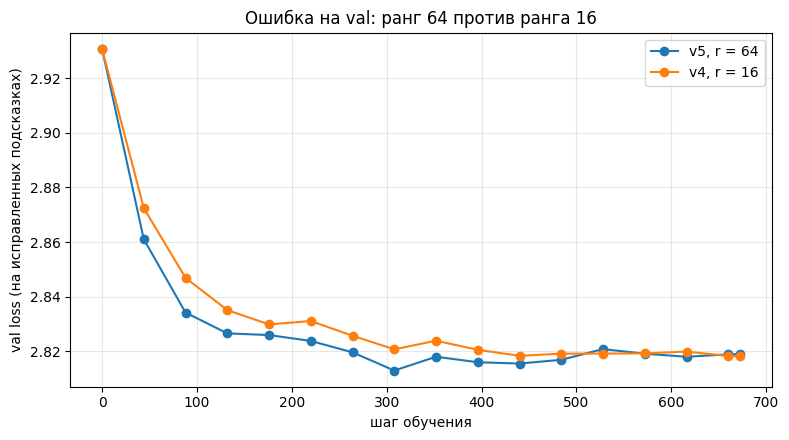

In [27]:
hist_v4_path = os.path.join(os.path.dirname(ADAPTER_V4), "history.json")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(hist_v5["val_step"], hist_v5["val_loss"], marker="o", label="v5, r = 64")
if os.path.exists(hist_v4_path):
    hist_v4 = json.load(open(hist_v4_path))
    ax.plot(hist_v4["val_step"], hist_v4["val_loss"], marker="o", label="v4, r = 16")
ax.set_xlabel("шаг обучения")
ax.set_ylabel("val loss (на исправленных подсказках)")
ax.set_title("Ошибка на val: ранг 64 против ранга 16")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "exp3_val_loss.png"), dpi=150)
plt.show()

### Перплексия на исправленных val и test

In [28]:
def ppl_on(adapter_dir):
    # Перплексия модели (с адаптером или без) на val и test с исправленными подсказками
    model = AutoModelForCausalLM.from_pretrained(MEDIUM)
    if adapter_dir is not None:
        model = PeftModel.from_pretrained(model, adapter_dir)
    model = model.to(device)
    out = (math.exp(eval_loss(model, val_items_f)), math.exp(eval_loss(model, test_items_f)))
    del model
    torch.cuda.empty_cache()
    return out


ppl_rows = {"medium: базовая": ppl_on(None),
            "medium: v4 (r = 16)": ppl_on(ADAPTER_V4),
            "medium: v5 (r = 64)": ppl_on(V5_ADAPTER)}
ppl_table = "| Модель | val перплексия | test перплексия |\n|---|---|---|\n"
for name, (v, t) in ppl_rows.items():
    ppl_table += f"| {name} | {v:.1f} | {t:.1f} |\n"
print(ppl_table)
with open(os.path.join(OUT_DIR, "exp3_perplexity.md"), "w", encoding="utf-8") as f:
    f.write(ppl_table)

Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


| Модель | val перплексия | test перплексия |
|---|---|---|
| medium: базовая | 18.7 | 16.2 |
| medium: v4 (r = 16) | 16.7 | 14.1 |
| medium: v5 (r = 64) | 16.7 | 14.0 |



## 8. Следование подсказке на 250 тестовых подсказках

v4 и v5 пишут главы по одним и тем же 250 подсказкам в двух постановках (исходные подсказки, герои главы). Доверительные интервалы считаются бутстрепом, разница v5 − v4 парная.

In [29]:
eval_big = pick_eval_set(test_raw, tok, n=250)
eval_big_f = [keep_chapter_heroes(ex) or ex for ex in eval_big]
prompts_big = [ex["prompt"] for ex in eval_big]
prompts_big_f = [ex["prompt"] for ex in eval_big_f]
print("Подсказок в большой выборке:", len(prompts_big))

MODELS = [("v4", "v4 (r = 16)", ADAPTER_V4), ("v5", "v5 (r = 64)", V5_ADAPTER)]
big_cov, big_res = {}, {}
for tag, pr in [("исходные подсказки", prompts_big), ("герои главы", prompts_big_f)]:
    for key, label, adapter in MODELS:
        name = f"большая выборка: {label} [{tag}]"
        r, g = run_variants(MEDIUM, adapter, {name: GEN}, pr, OUT_DIR, tok)
        big_res.update(r)
        pairs = [(i, c) for i, c in enumerate(per_prompt_coverage(pr, g[name])) if c is not None]
        big_cov[(key, tag)] = dict(pairs)

lines = ["| Постановка | Модель | Охват героев (95 % ИД) | Все герои названы | Повторы |", "|---|---|---|---|---|"]
for tag in ["исходные подсказки", "герои главы"]:
    for key, label, _ in MODELS:
        cov = big_cov[(key, tag)]
        vals = [cov[i] for i in sorted(cov)]
        lo, hi = bootstrap_ci(vals)
        res = big_res[f"большая выборка: {label} [{tag}]"]
        lines.append(f"| {tag} | {label} | {sum(vals) / len(vals):.0%} ({lo:.0%}–{hi:.0%}) | "
                     f"{res['all_heroes']:.0%} | {res['repeat3']:.1%} |")
table_big = "\n".join(lines)
print(table_big)

print()
for tag in ["исходные подсказки", "герои главы"]:
    a, b = big_cov[("v5", tag)], big_cov[("v4", tag)]
    common = sorted(set(a) & set(b))
    d, lo, hi = paired_diff_ci([a[i] for i in common], [b[i] for i in common])
    verdict = "различие значимо" if lo > 0 or hi < 0 else "различие в пределах шума"
    print(f"{tag}: v5 − v4 = {d:+.1%} (95 % ИД {lo:+.1%} … {hi:+.1%}), {verdict}")

with open(os.path.join(OUT_DIR, "exp3_metrics.md"), "w", encoding="utf-8") as f:
    f.write(table_big)

Подсказок в большой выборке: 250


Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


большая выборка: v4 (r = 16) [исходные подсказки]: готово за 3.3 мин
    {'hero_coverage': 0.497, 'all_heroes': 0.128, 'junk': 0.0, 'repeat3': 0.016, 'words': 222.376, 'n': 250}


Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (3 outputs left out)

большая выборка: v4 (r = 16) [герои главы]: готово за 3.1 мин
    {'hero_coverage': 0.597, 'all_heroes': 0.348, 'junk': 0.0, 'repeat3': 0.016, 'words': 224.88, 'n': 250}


Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


большая выборка: v5 (r = 64) [герои главы]: готово за 3.2 мин
    {'hero_coverage': 0.605, 'all_heroes': 0.336, 'junk': 0.0, 'repeat3': 0.016, 'words': 220.384, 'n': 250}
| Постановка | Модель | Охват героев (95 % ИД) | Все герои названы | Повторы |
|---|---|---|---|---|
| исходные подсказки | v4 (r = 16) | 50% (46%–53%) | 13% | 1.6% |
| исходные подсказки | v5 (r = 64) | 49% (45%–52%) | 12% | 1.8% |
| герои главы | v4 (r = 16) | 60% (55%–64%) | 35% | 1.6% |
| герои главы | v5 (r = 64) | 61% (56%–65%) | 34% | 1.6% |

исходные подсказки: v5 − v4 = -0.9% (95 % ИД -4.2% … +2.5%), различие в пределах шума
герои главы: v5 − v4 = +0.9% (95 % ИД -3.3% … +5.0%), различие в пределах шума


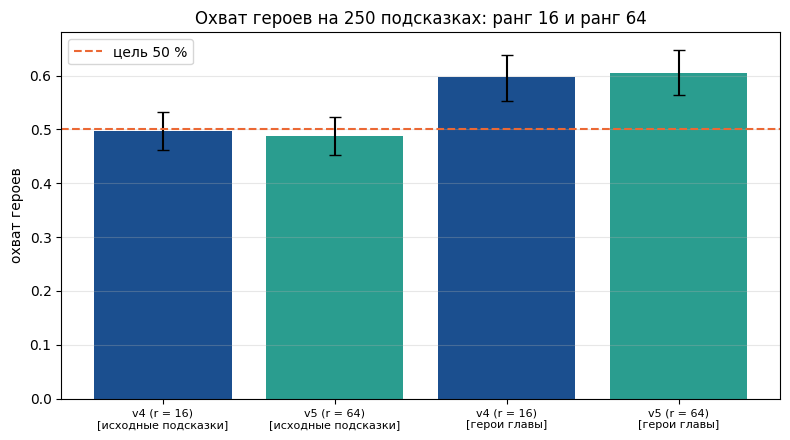

In [30]:
# График: охват героев, v4 и v5, с доверительными интервалами
fig, ax = plt.subplots(figsize=(8, 4.5))
labels, means, errs = [], [], []
for tag in ["исходные подсказки", "герои главы"]:
    for key, label, _ in MODELS:
        cov = big_cov[(key, tag)]
        vals = [cov[i] for i in sorted(cov)]
        lo, hi = bootstrap_ci(vals)
        m = sum(vals) / len(vals)
        labels.append(f"{label}\n[{tag}]")
        means.append(m)
        errs.append((m - lo, hi - m))
ax.bar(range(len(means)), means, yerr=list(zip(*errs)), color=["#1b4f8f", "#2a9d8f"] * 2, capsize=4)
ax.axhline(0.5, color="#eb6834", linestyle="--", label="цель 50 %")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("охват героев")
ax.set_title("Охват героев на 250 подсказках: ранг 16 и ранг 64")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "exp3_rank64.png"), dpi=150)
plt.show()

### Вывод по эксперименту 3

**Гипотеза 3 не подтвердилась: ранг 64 не дал выигрыша.** Адаптер v5 (r = 64, 25,2 млн обучаемых параметров) в четыре раза больше, чем v4 (r = 16, 6,29 млн), но ни перплексия, ни следование подсказке не улучшились.

| | v4 (r = 16) | v5 (r = 64) |
|---|---|---|
| Перплексия val / test (исправленные подсказки) | 16,7 / 14,1 | 16,7 / 14,0 |
| Охват героев, исходные подсказки (250) | 50 % (46–53) | 49 % (45–52) |
| Охват героев, герои главы (250) | 60 % (55–64) | 61 % (56–65) |
| Все герои названы, исходные / герои главы | 13 % / 35 % | 12 % / 34 % |

- **Перплексия:** обе модели лучше базовой (18,7 / 16,2) и между собой неразличимы (разница на test 0,1).
- **Следование подсказке:** разница v5 − v4 равна −0,9 п.п. (95 % ИД −4,2 … +2,5) на исходных подсказках и +0,9 п.п. (−3,3 … +5,0) на подсказках с героями главы. Оба интервала содержат ноль: различие в пределах шума.
- **Кривая обучения:** лучшая ошибка на val у v5 на шаге 308 (2,813), дальше val не падает, а train продолжает снижаться (2,47 к концу): модель с большим рангом начинает подстраиваться под обучающие данные, но не обобщает лучше.
- **Что это значит:** ёмкость адаптера не ограничивает следование подсказке. Узкое место в данных: в обучающих примерах герои часто называются только в соседних главах, а объём корпуса мал (около 2700 примеров).
- **Решение:** финальной остаётся модель v4 (r = 16): точность та же, обучаемых параметров в четыре раза меньше.
- **Воспроизводимость:** v4 на тех же 250 подсказках здесь дала 50 % / 60 %, в ноутбуке 2 при другом прогоне 48 % / 60 %. Разброс генерации на GPU порядка 1–2 п.п., меньшие различия трактовать нельзя.